# 7 · Dériver à travers un solveur : l'état adjoint

*Notebook 7 du cours. Il suppose les notebooks 5 (solveurs, factorisation réutilisable) et 6 (opérateur sans matrice, `dK_contract`). La différentiation automatique, qui avait une leçon dédiée dans le plan initial, est rappelée ici dans la mesure où elle sert.*

L'optimisation topologique modifie la densité $\rho_e$ de **chaque** élément (des milliers à des centaines de milliers de variables) pour faire baisser un coût $J$, par exemple la compliance $J=\mathbf f^\top\mathbf u$. Les optimiseurs (notebooks 8 à 10) ont besoin du **gradient** $\partial J/\partial\rho_e$ pour tous les éléments à chaque itération. Or $J$ dépend de $\rho$ **à travers la solution d'un système linéaire** : $\widetilde{\mathbf K}(w)\,\mathbf u=\mathbf P\mathbf f$. Comment dériver à travers une résolution ?

**Plan.**
1. La différentiation automatique en bref : graphe, mode inverse, ce que fait `loss.backward()`, pièges ;
2. Un premier adjoint à la main : la barre 1D, où tout se calcule ;
3. L'état adjoint en général : la dérivation ;
4. Dériver *à travers les itérations* du solveur, et pourquoi on ne le fait pas ;
5. L'implémentation `solve_spd` (`src/aeroptimizer/fem/adjoint.py`) ;
6. Validation : différences finies, `gradcheck`, formule analytique de la compliance ;
7. Un coût autre que la compliance : $\boldsymbol\lambda\neq\mathbf u$ ;
8. Coût et limites.

Ce notebook promeut dans `src` la fonction `solve_spd` (une `torch.autograd.Function` dont le backward est l'équation adjointe) et ses contrats C-SOLVE-03 à 06.

In [1]:
import sys, time, math, inspect
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.fem import elements as el
from aeroptimizer.fem.adjoint import SolveSPD, solve_spd
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.fem.solvers import ScipyDirect, TorchCG, conjugate_gradient, jacobi_preconditioner
from aeroptimizer.grid import Grid, Connectivity
from aeroptimizer.materials import Orthotropic

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. La différentiation automatique en bref

Un programme numérique est une composition de fonctions élémentaires (somme, produit, `sin`, produit matrice-vecteur…). La règle de dérivation en chaîne s'applique à chacune. **PyTorch** (comme tout outil d'*autograd*) enregistre cette composition dans un **graphe de calcul** au moment où le programme s'exécute, puis `backward()` parcourt le graphe **en sens inverse** (mode inverse, *reverse mode*) pour appliquer la règle de la chaîne.

Le point clé est ce que le mode inverse calcule. Pour une fonction $\mathbf y=F(\mathbf x)$ de jacobienne $\mathbf J_F$, et un vecteur $\mathbf g$ (le « gradient entrant »), il calcule le produit $\mathbf g^\top\mathbf J_F$ (produit *vecteur–jacobienne*) **sans jamais former** $\mathbf J_F$. Si le coût final $J$ est un scalaire, on part de $g=1$ et on obtient les $n$ dérivées $\partial J/\partial x_i$ pour un coût de l'ordre de **un ou deux** calculs de $J$, quel que soit $n$. À l'inverse, les différences finies exigent $n+1$ évaluations de $J$.

In [2]:
# Une fonction scalaire de n variables : J(x) = sum( tanh(A x)^2 )
def make(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    return torch.randn(n, n, generator=g) / math.sqrt(n), torch.randn(n, generator=g)

A, x = make(5)
x = x.requires_grad_()
J = (torch.tanh(A @ x) ** 2).sum()
J.backward()                                        # remplit x.grad
print("autograd :", x.grad.numpy())

# dérivée analytique : dJ/dx = A^T (2 tanh(Ax) (1 - tanh(Ax)^2))
t = torch.tanh(A @ x.detach())
print("analytique:", (A.T @ (2 * t * (1 - t**2))).numpy())

# différences finies centrées : 2n évaluations de J
def J_of(v): return (torch.tanh(A @ v) ** 2).sum()
fd = torch.stack([(J_of(x.detach() + 1e-6 * e) - J_of(x.detach() - 1e-6 * e)) / 2e-6 for e in torch.eye(5)])
print("diff. finies:", fd.numpy())
print("graphe : J.grad_fn =", J.grad_fn, "->", [type(n).__name__ for n, _ in J.grad_fn.next_functions])

autograd : [ 1.044  -0.2548  0.4666  0.0351  0.0846]
analytique: [ 1.044  -0.2548  0.4666  0.0351  0.0846]
diff. finies: [ 1.044  -0.2548  0.4666  0.0351  0.0846]
graphe : J.grad_fn = <SumBackward0 object at 0x104368d90> -> ['PowBackward0']


Les trois colonnes coïncident. Le gain apparaît quand $n$ grandit : on chronomètre le gradient par autograd (une évaluation + un `backward`) contre les différences finies ($n+1$ évaluations), pour $J(\mathbf x)=\sum\tanh^2(\mathbf A\mathbf x)$.

In [3]:
print(f"{'n':>6} | {'autograd [ms]':>13} | {'diff. finies [ms]':>17} | rapport")
for n in (50, 200, 800):
    A, x = make(n)
    def J_of(v): return (torch.tanh(A @ v) ** 2).sum()
    def autograd_une_fois():
        xr = x.clone().requires_grad_(); J_of(xr).backward()
    def diff_finies():
        base = J_of(x)
        return [(J_of(x + 1e-7 * e) - base) / 1e-7 for e in torch.eye(n)]    # différences avant : n évaluations de plus
    def meilleur(fn, rep=7):
        fn(); ts = []
        for _ in range(rep):
            t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
        return min(ts)
    t_ad, t_fd = meilleur(autograd_une_fois), meilleur(diff_finies)
    print(f"{n:6d} | {t_ad * 1e3:13.2f} | {t_fd * 1e3:17.2f} | x{t_fd / t_ad:.0f}")

     n | autograd [ms] | diff. finies [ms] | rapport
    50 |          0.04 |              0.59 | x15
   200 |          0.06 |              3.56 | x60


   800 |          0.19 |             40.22 | x213


Le rapport croît avec $n$ (en théorie comme $n$ ; les chiffres exacts dépendent de la machine). Dans notre problème, $n$ est le nombre d'éléments : le mode inverse n'est pas un confort, c'est ce qui rend l'optimisation topologique possible.

**Trois pièges** à connaître dès maintenant, car ils reviennent dans tout le projet :
- les **opérations en place** (`y.add_(1)`) peuvent écraser une valeur dont le graphe a besoin : PyTorch le détecte au `backward` et s'arrête ;
- les fonctions **non dérivables** (`abs` en 0, `min`, `max`) ont une dérivée arbitraire au point de rupture (ici 0 pour `abs`) : l'autograd ne le signale pas ;
- `detach()` coupe le graphe : ce qui passe par `.numpy()` ou `float(...)` n'est plus différentiable.

In [4]:
x = torch.tensor([0.0, 2.0], requires_grad=True)
print("abs'(0) donné par autograd :", torch.autograd.grad(x.abs().sum(), x)[0].numpy(), "(la vraie 'dérivée' en 0 n'existe pas)")

y = torch.tensor([1.0, 2.0], requires_grad=True)
z = y.exp()
z.add_(1.0)                                         # modification en place de la sortie de exp
try:
    z.sum().backward()
except RuntimeError as e:
    print("opération en place :", str(e)[:95], "...")

abs'(0) donné par autograd : [0. 1.] (la vraie 'dérivée' en 0 n'existe pas)
opération en place : one of the variables needed for gradient computation has been modified by an inplace operation: ...


## 2. Un premier adjoint à la main : la barre 1D

Une barre de $n$ éléments (notebook 2), encastrée en $x=0$ et tirée par une force $F=1$ à son extrémité, avec une rigidité $w_e$ par élément ($w_e=EA/\ell$). La matrice élémentaire est $w_e\begin{psmallmatrix}1&-1\\-1&1\end{psmallmatrix}$ et le déplacement de l'extrémité est $u_n=\sum_e F/w_e$. La compliance vaut donc

$$
J=\mathbf f^\top\mathbf u=F\,u_n=\sum_e\frac1{w_e}\qquad\Longrightarrow\qquad\frac{\partial J}{\partial w_e}=-\frac1{w_e^2}.
$$

C'est un **oracle exact**. Voyons ce que donnent les outils : l'autograd à travers `torch.linalg.solve` (dense), et la formule adjointe $\partial J/\partial w_e=-\boldsymbol\lambda_e^\top\mathbf K_e^0\mathbf u_e$ avec $\boldsymbol\lambda=\mathbf u$ pour la compliance.

In [5]:
n = 6
w = (1.0 + torch.arange(n, dtype=torch.float64)).requires_grad_()       # rigidités 1, 2, ..., 6
Ke0 = torch.tensor([[1.0, -1.0], [-1.0, 1.0]])

def solve_bar(w):
    K = torch.zeros(n + 1, n + 1)
    for e in range(n):
        K[e:e + 2, e:e + 2] = K[e:e + 2, e:e + 2] + w[e] * Ke0           # assemblage
    Kt = K[1:, 1:]                                                       # nœud 0 encastré : on le supprime
    f = torch.zeros(n); f[-1] = 1.0
    return torch.linalg.solve(Kt, f), f

u, f = solve_bar(w)
J = f @ u
J.backward()
print("J =", J.item(), " (formule : somme des 1/w_e =", (1 / w.detach()).sum().item(), ")")
print("autograd dense  :", w.grad.numpy())
print("exact -1/w_e^2  :", (-1 / w.detach() ** 2).numpy())

# formule adjointe : lambda = u, dJ/dw_e = - u_e^T Ke0 u_e, avec u_e = (u_{e}, u_{e+1}) (u_0 = 0)
ufull = torch.cat([torch.zeros(1), u.detach()])
ue = torch.stack([ufull[:-1], ufull[1:]], dim=1)
print("formule adjointe:", (-(ue @ Ke0 * ue).sum(-1)).numpy())

J = 2.450000000000005  (formule : somme des 1/w_e = 2.4499999999999997 )
autograd dense  : [-1.     -0.25   -0.1111 -0.0625 -0.04   -0.0278]
exact -1/w_e^2  : [-1.     -0.25   -0.1111 -0.0625 -0.04   -0.0278]
formule adjointe: [-1.     -0.25   -0.1111 -0.0625 -0.04   -0.0278]


Les trois résultats sont identiques. Remarquons que `torch.linalg.solve` sait dériver tout seul : **sa règle de dérivation interne est précisément un état adjoint** (une résolution supplémentaire avec la même matrice transposée), et non un déroulé de l'élimination de Gauss. Le projet doit écrire sa propre règle parce que son solveur est soit un **solveur creux externe** (SciPy : l'autograd ne voit pas à l'intérieur), soit un **CG sans matrice** qu'on ne veut pas dérouler (§4).

## 3. L'état adjoint en général

Soit $J(\mathbf u,w)$ un coût (scalaire) où $\mathbf u$ résout $\widetilde{\mathbf K}(w)\,\mathbf u=\mathbf P\mathbf f$. On veut $\mathrm dJ/\mathrm dw_e$. La règle de la chaîne donne
$$
\frac{\mathrm dJ}{\mathrm dw_e}=\frac{\partial J}{\partial w_e}+\frac{\partial J}{\partial\mathbf u}\,\frac{\mathrm d\mathbf u}{\mathrm dw_e},
$$
et $\mathrm d\mathbf u/\mathrm dw_e$ est un vecteur de $N$ inconnues **par élément** : l'obtenir pour tous les $e$ coûterait $N_e$ résolutions. L'astuce : on dérive l'équation d'état,
$$
\widetilde{\mathbf K}\,\frac{\mathrm d\mathbf u}{\mathrm dw_e}=-\frac{\partial\widetilde{\mathbf K}}{\partial w_e}\,\mathbf u
\quad\Longrightarrow\quad
\frac{\mathrm d\mathbf u}{\mathrm dw_e}=-\widetilde{\mathbf K}^{-1}\frac{\partial\widetilde{\mathbf K}}{\partial w_e}\mathbf u,
$$
(à $\mathbf f$ fixé), et on reporte :
$$
\frac{\partial J}{\partial\mathbf u}\frac{\mathrm d\mathbf u}{\mathrm dw_e}
=-\underbrace{\Big(\widetilde{\mathbf K}^{-\top}\Big(\frac{\partial J}{\partial\mathbf u}\Big)^{\!\top}\Big)^{\!\top}}_{\boldsymbol\lambda^\top}\frac{\partial\widetilde{\mathbf K}}{\partial w_e}\mathbf u .
$$
Le vecteur $\boldsymbol\lambda$ **ne dépend pas de $e$** : c'est la solution d'**une seule** résolution, l'**équation adjointe**
$$
\boxed{\ \widetilde{\mathbf K}^\top\boldsymbol\lambda=\Big(\frac{\partial J}{\partial\mathbf u}\Big)^{\!\top}\ }\qquad\text{et, avec }\widetilde{\mathbf K}=\widetilde{\mathbf K}^\top,\qquad
\frac{\mathrm dJ}{\mathrm dw_e}=\frac{\partial J}{\partial w_e}-\boldsymbol\lambda_e^\top\mathbf K_e^0\,\mathbf u_e .
$$
Parce que $\widetilde{\mathbf K}(w)=\sum_e w_e\,\mathbf A_e^\top\mathbf K_e^0\mathbf A_e$ (notebook 6, avec masquage des appuis), la dérivée $\partial\widetilde{\mathbf K}/\partial w_e$ est la matrice élémentaire $\mathbf K_e^0$ ; la somme sur tous les éléments est la contraction `dK_contract(lam, u)` du notebook 6. Si la force dépend du design ($\mathbf f=\mathbf f(w)$), on ajoute $\boldsymbol\lambda^\top\partial(\mathbf P\mathbf f)/\partial w_e$ : le backward renvoie donc aussi $\partial J/\partial\mathbf f=\mathbf P\boldsymbol\lambda$.

Pour la compliance $J=\mathbf f^\top\mathbf u$, $\partial J/\partial\mathbf u=\mathbf f^\top$, donc $\boldsymbol\lambda=\mathbf u$ (mathématiquement, aucune résolution en plus ; le code générique de `src` ne s'en sert pas et fait la résolution adjointe, qui vaut $\mathbf u$ à la précision du solveur) et $\mathrm dJ/\mathrm dw_e=-\mathbf u_e^\top\mathbf K_e^0\mathbf u_e\le0$ : ajouter de la matière ne fait jamais monter la compliance. En général il faut **une** résolution supplémentaire, avec la **même** factorisation (notebook 5, contrat C-SOLVE-01).

## 4. Dériver à travers les itérations du solveur ?

Puisque le CG est écrit en PyTorch (notebook 5) avec `op.matvec` (notebook 6), l'autograd *peut* le dériver tel quel : chaque itération est une suite d'opérations différentiables. Ce **déroulé** (*unrolling*) donne un gradient sans écrire de règle. Comparons-le à l'adjoint sur une poutre MBB $30\times10$ avec une densité aléatoire et $w=\varepsilon_s+(1-\varepsilon_s)\rho^3$. On mesure l'erreur sur le gradient par rapport à la référence exacte (adjoint avec solveur direct), la mémoire des tenseurs que le graphe a dû conserver, et les temps.

In [6]:
def mbb(nx, nz):
    # demi-poutre MBB : symétrie sur x = 0 (u_x = 0), rouleau en bas à droite (u_z = 0), force unitaire en haut à gauche
    g = Grid((nx, nz), (1.0, 1.0))
    Ke0 = el.elasticity_ke0(2, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(2, "stress"))
    nzn = nz + 1
    fixed = torch.zeros(g.n_dofs(2), dtype=torch.bool)
    fixed[0 : 2 * nzn : 2] = True
    fixed[2 * (g.n_nodes - nzn) + 1] = True
    f = torch.zeros(g.n_dofs(2)); f[2 * (nzn - 1) + 1] = -1.0
    return StructuredFEOperator(g, Connectivity(g, 2), Ke0, 2, fixed), f

p, eps_s = 3.0, 1e-3
op, f = mbb(30, 10)
rho0 = 0.2 + 0.8 * torch.rand(op.grid.n_elems, generator=torch.Generator().manual_seed(0))
simp = lambda r: eps_s + (1 - eps_s) * r**p

def grad_adjoint(solver):
    r = rho0.clone().requires_grad_()
    u = solve_spd(op, simp(r), f, solver)
    (f @ u).backward()
    return r.grad

g_exact = grad_adjoint(ScipyDirect())                   # référence : adjoint, solveur direct

class Memoire:
    # somme la taille des tenseurs que l'autograd garde pour le backward
    def __init__(self): self.octets = 0; self.n = 0
    def pack(self, t): self.octets += t.numel() * t.element_size(); self.n += 1; return t
    def unpack(self, t): return t

print(f"{'tol CG':>7} | {'itér.':>5} | {'err. déroulé':>12} | {'err. adjoint':>12} | {'mémoire déroulé':>15} | {'backward déroulé':>16}")
for tol in (1e-2, 1e-4, 1e-6, 1e-8, 1e-10):
    r = rho0.clone().requires_grad_()
    w = simp(r)
    m = Memoire()
    with torch.autograd.graph.saved_tensors_hooks(m.pack, m.unpack):
        res = conjugate_gradient(lambda v: op.matvec(w, v), f * op.free_mask,
                                 preconditioner=jacobi_preconditioner(op.diag(w)), tol=tol)
        J = f @ res.x
    t0 = time.perf_counter(); J.backward(); t_bw = time.perf_counter() - t0
    err_un = float((r.grad - g_exact).norm() / g_exact.norm())
    err_ad = float((grad_adjoint(TorchCG(tol=tol)) - g_exact).norm() / g_exact.norm())
    print(f"{tol:7.0e} | {res.iterations:5d} | {err_un:12.1e} | {err_ad:12.1e} | {m.octets / 2**20:10.1f} Mo | {t_bw * 1e3:13.1f} ms")

 tol CG | itér. | err. déroulé | err. adjoint | mémoire déroulé | backward déroulé
  1e-02 |   197 |      2.3e-04 |      5.4e-04 |       27.5 Mo |          23.9 ms
  1e-04 |   224 |      2.7e-07 |      7.5e-06 |       31.2 Mo |          27.2 ms


  1e-06 |   246 |      2.1e-08 |      5.4e-08 |       34.3 Mo |          29.8 ms
  1e-08 |   267 |      1.0e-11 |      5.0e-10 |       37.2 Mo |          31.5 ms
  1e-10 |   286 |      2.5e-12 |      7.6e-12 |       39.8 Mo |          37.4 ms


Ce que dit le tableau :

- **Précision** : à tolérance égale, les deux gradients ont une erreur qui suit la tolérance du CG ; celle du déroulé est même un peu plus faible (d'un facteur 2 à 50 ici). Dériver à travers les itérations n'est donc *pas* moins précis dans ce cas : l'argument en faveur de l'adjoint n'est pas là.
- **Mémoire** : le déroulé conserve des tenseurs à chaque itération (de l'ordre de 40 Mo ici, pour 286 itérations et seulement 300 éléments). Cette mémoire croît comme (nombre d'itérations) $\times$ (taille du problème) : en extrapolant linéairement ce rapport au budget 3D du projet (96 000 éléments, ~1000 itérations), on obtient de l'ordre de **45 Go** (et davantage en 3D, où chaque élément porte 24 degrés de liberté au lieu de 8), hors de portée d'un portable. L'adjoint ne conserve qu'un vecteur $\mathbf u$ (2,5 Mo au budget 3D).
- **Temps** : le `backward` déroulé coûte autant que toutes les itérations ; l'adjoint coûte **une** résolution (et avec un solveur direct dont la factorisation est déjà faite, une simple substitution).
- **Généralité** : le déroulé est impossible avec un solveur direct externe (SciPy) : l'autograd ne voit pas à l'intérieur de `splu`. L'adjoint marche avec **n'importe quel** solveur, car il ne dérive que l'équation d'état.

C'est donc la mémoire et l'indépendance vis-à-vis du solveur qui justifient l'adjoint, pas la précision.

## 5. L'implémentation : `solve_spd`

L'autograd permet d'enregistrer sa propre règle de dérivation : on écrit une sous-classe de `torch.autograd.Function` avec une méthode `forward` (le calcul) et une méthode `backward` (le produit vecteur–jacobienne). Voici le code de `src`.

In [7]:
print(inspect.getsource(SolveSPD))

class SolveSPD(torch.autograd.Function):
    """u = K~(w)^{-1} P f. Backward = adjoint equation: ONE extra solve with the same handle.

    The handle (factorisation, or the CG matvec) is kept on `ctx`, so the backward needs no
    refactorisation and the solver iterations are never recorded in the autograd graph. Not
    twice-differentiable (`once_differentiable`): the Hessian is not needed by the optimisers.
    """

    @staticmethod
    def forward(ctx, w, f, op: StructuredFEOperator, solver: LinearSolver):  # type: ignore[override]
        handle = solver.prepare(op, w.detach())
        u = handle.solve(f.detach() * op.free_mask)
        ctx.op, ctx.handle = op, handle
        ctx.save_for_backward(u)
        return u

    @staticmethod
    @once_differentiable
    def backward(ctx, g_u):  # type: ignore[override]
        need_w, need_f = ctx.needs_input_grad[0], ctx.needs_input_grad[1]
        if not (need_w or need_f):
            return None, None, None, None
        (u,) = ct

Quelques points de lecture :

- `forward` utilise `w.detach()` et `f.detach()` : **aucune** opération du solveur n'est enregistrée dans le graphe. Il ne reste dans le graphe qu'un seul nœud (`SolveSPDBackward`) avec le vecteur $\mathbf u$ et le *handle* du solveur (factorisation, ou fonction `matvec`) gardés en mémoire.
- `backward(g_u)` reçoit $\mathbf g=\partial J/\partial\mathbf u$ (le gradient entrant), résout $\widetilde{\mathbf K}\boldsymbol\lambda=\mathbf P\mathbf g$ avec le **même** handle, puis renvoie $-\boldsymbol\lambda_e^\top\mathbf K_e^0\mathbf u_e$ pour `w` et $\mathbf P\boldsymbol\lambda$ pour `f`. `needs_input_grad` évite de calculer ce dont personne n'a besoin.
- `once_differentiable` : on ne peut pas dériver deux fois à travers `solve_spd` (le projet n'a pas besoin du hessien).
- Tout ce qui est **en amont** (SIMP, filtres, surplomb…) est de l'autograd ordinaire qui se branche sur le `grad_w` renvoyé : c'est la seule dérivée écrite à la main du projet (CONTRACTS C-DIFF-03).

## 6. Validation

Trois vérifications indépendantes sur une console $6\times4$ : (a) différences finies sur le coût compliance, (b) `gradcheck` (autograd contre différences finies sur tout le jacobien, pour `w` **et** pour `f`), (c) la formule analytique $-p(1-\varepsilon_s)\rho_e^{p-1}\mathbf u_e^\top\mathbf K_e^0\mathbf u_e$ de la compliance.

In [8]:
def console(shape):
    g = Grid(shape, (1.0, 1.0))
    Ke0 = el.elasticity_ke0(2, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(2, "stress"))
    nz = shape[1] + 1
    fixed = torch.zeros(g.n_dofs(2), dtype=torch.bool); fixed[: 2 * nz] = True      # encastrée sur x = 0
    f = torch.zeros(g.n_dofs(2)); f[2 * (g.n_nodes - 1) + 1] = -1.0                  # force au coin libre
    return StructuredFEOperator(g, Connectivity(g, 2), Ke0, 2, fixed), f

op6, f6 = console((6, 4))
gen = torch.Generator().manual_seed(1)
rho = 0.2 + 0.8 * torch.rand(op6.grid.n_elems, generator=gen)
direct = ScipyDirect()

# (a) différences finies centrées sur la compliance
def compliance(r): return f6 @ solve_spd(op6, simp(r), f6, direct)
r = rho.clone().requires_grad_(); compliance(r).backward()
fd = torch.empty_like(rho)
for e in range(len(rho)):
    d = torch.zeros_like(rho); d[e] = 1e-4
    fd[e] = (compliance(rho + d) - compliance(rho - d)) / 2e-4
print("(a) adjoint vs différences finies, écart relatif max :", float(((r.grad - fd).abs() / fd.abs()).max()))

# (b) gradcheck en float64 : jacobien complet par rapport à w, puis à f
w = (0.1 + torch.rand(op6.grid.n_elems, generator=gen)).requires_grad_()
ff = torch.randn(op6.n_dofs, generator=gen).requires_grad_()
ok = torch.autograd.gradcheck(lambda ww, fv: solve_spd(op6, ww, fv, direct), (w, ff), rtol=1e-6, atol=1e-6)
print("(b) gradcheck (jacobiens en w et en f) :", ok)

# (c) formule analytique de la compliance
ue = (lambda u: u[op6.edof])(solve_spd(op6, simp(rho), f6, direct))
analytique = -p * (1 - eps_s) * rho ** (p - 1) * (ue @ op6.Ke0 * ue).sum(-1)
print("(c) écart relatif à la formule analytique :", float(((r.grad - analytique).abs() / analytique.abs()).max()))

(a) adjoint vs différences finies, écart relatif max : 2.27896956046079e-07


(b) gradcheck (jacobiens en w et en f) : True
(c) écart relatif à la formule analytique : 2.4901613490089433e-16


Les trois vérifications passent : (a) à la précision des différences finies (le tableau affiche l'écart relatif au pire élément), (b) `gradcheck` vrai, (c) formule analytique à la précision machine. On vérifie aussi que le backward fait ce que le contrat annonce : **une** factorisation et **une** résolution supplémentaire, et rien d'autre dans le graphe.

In [9]:
class Compteur:
    # enveloppe un solveur et compte les factorisations (prepare) et les résolutions (solve)
    def __init__(self, interne): self.interne, self.n_prepare, self.n_solve = interne, 0, 0
    def prepare(self, op, w):
        self.n_prepare += 1
        h, me = self.interne.prepare(op, w), self
        class H:
            def solve(self, b, **kw): me.n_solve += 1; return h.solve(b, **kw)
        return H()

for nom, interne in (("direct", ScipyDirect()), ("CG", TorchCG(tol=1e-12))):
    c = Compteur(interne)
    r = rho.clone().requires_grad_()
    u = solve_spd(op6, simp(r), f6, c)
    apres_forward = (c.n_prepare, c.n_solve)
    voisins = [type(n).__name__ for n, _ in u.grad_fn.next_functions]
    (f6 @ u).backward()
    print(f"{nom:>6} : après forward (factorisations, résolutions) = {apres_forward}, après backward = {(c.n_prepare, c.n_solve)}; "
          f"graphe : {type(u.grad_fn).__name__} -> {voisins}")

direct : après forward (factorisations, résolutions) = (1, 1), après backward = (1, 2); graphe : SolveSPDBackward -> ['AddBackward0', 'NoneType']
    CG : après forward (factorisations, résolutions) = (1, 1), après backward = (1, 2); graphe : SolveSPDBackward -> ['AddBackward0', 'NoneType']


Un `forward` fait une préparation et une résolution ; le `backward` ajoute **une** résolution, sans nouvelle préparation, et le graphe sous `solve_spd` se réduit à la chaîne SIMP qui mène à $\rho$ (`AddBackward0`) : aucune itération du solveur n'est enregistrée, pour le solveur direct comme pour le CG.

Enfin, le gradient doit aussi traverser une **charge qui dépend du design**, $\mathbf f=\mathbf B\,\rho$ (un poids propre, par exemple). Test par différences finies sur $J=\mathbf g^\top\mathbf u$ avec $\mathbf B$ aléatoire :

In [10]:
B = torch.randn(op6.n_dofs, op6.grid.n_elems, generator=gen)
gvec = torch.randn(op6.n_dofs, generator=gen)
def J_load(r): return gvec @ solve_spd(op6, 0.1 + r, B @ r, direct)
r = rho.clone().requires_grad_(); J_load(r).backward()
for e in (0, 7, 20):
    d = torch.zeros_like(rho); d[e] = 1e-4
    fd_e = (J_load(rho + d) - J_load(rho - d)) / 2e-4
    print(f"élément {e:2d} : autograd {float(r.grad[e]):+.6f}   différences finies {float(fd_e):+.6f}")

élément  0 : autograd +1722.964535   différences finies +1722.964604
élément  7 : autograd +203.320608   différences finies +203.320610
élément 20 : autograd -781.700682   différences finies -781.700681


## 7. Un coût autre que la compliance : $\boldsymbol\lambda\neq\mathbf u$

Prenons le déplacement horizontal $J=u_x$ d'un nœud au milieu de la face inférieure de la poutre MBB $60\times20$ (densité uniforme $\rho=0{,}5$). Ici $\partial J/\partial\mathbf u=\mathbf e_k$ (un vecteur nul sauf en un degré de liberté) et l'adjoint $\boldsymbol\lambda=\widetilde{\mathbf K}^{-1}\mathbf e_k$ est la **réponse de la structure à une force unitaire placée au point où on mesure**. Le gradient est de signe variable : renforcer certaines zones diminue $u_x$, en renforcer d'autres l'augmente. On compare avec la compliance, puis on vérifie quelques éléments par différences finies.

u_x du nœud = 162.2 ; part des éléments à gradient négatif : 74%
élément |  adjoint   | diff. finies
    323 | -2.9711e+00 | -2.9711e+00
    761 | +1.6513e-01 | +1.6513e-01
    611 | -1.6144e-01 | -1.6144e-01
    369 | -7.4623e-02 | -7.4623e-02
     49 | -2.2232e-01 | -2.2232e-01
   1016 | +2.1353e-04 | +2.1343e-04


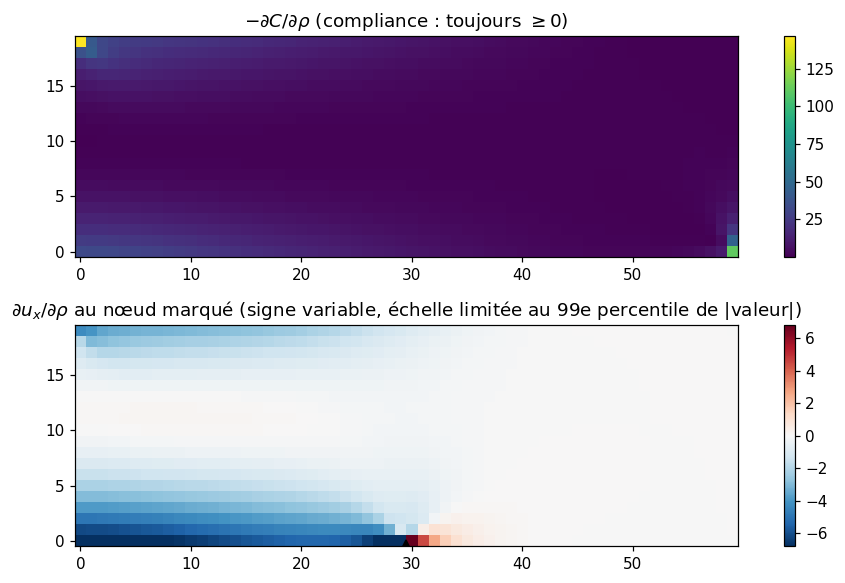

In [11]:
nx, nz = 60, 20
opm, fm = mbb(nx, nz)
rho_u = torch.full((opm.grid.n_elems,), 0.5)
k = 2 * ((nx // 2) * (nz + 1))                          # ddl x du nœud (x = 30, z = 0)
e_k = torch.zeros(opm.n_dofs); e_k[k] = 1.0

def grad_of(cout, solver=ScipyDirect()):
    r = rho_u.clone().requires_grad_()
    u = solve_spd(opm, simp(r), fm, solver)
    cout(u).backward()
    return r.grad, u.detach()

g_C, u_ref = grad_of(lambda u: fm @ u)                  # compliance
g_U, _ = grad_of(lambda u: e_k @ u)                     # déplacement u_x du nœud k
print(f"u_x du nœud = {float(u_ref[k]):.1f} ; part des éléments à gradient négatif : {float((g_U < 0).double().mean()):.0%}")

# vérification par différences finies sur 6 éléments pris au hasard
rng = np.random.default_rng(0)
print("élément |  adjoint   | diff. finies")
for e in rng.choice(opm.grid.n_elems, 6, replace=False):
    d = torch.zeros_like(rho_u); d[e] = 1e-4
    val = lambda r: float(e_k @ solve_spd(opm, simp(r), fm, ScipyDirect()))
    print(f"{e:7d} | {float(g_U[e]):+.4e} | {(val(rho_u + d) - val(rho_u - d)) / 2e-4:+.4e}")

fig, axs = plt.subplots(2, 1, figsize=(9, 5.4))
for ax, g, titre, cmap in ((axs[0], -g_C, r"$-\partial C/\partial\rho$ (compliance : toujours $\geq 0$)", "viridis"),
                           (axs[1], g_U, r"$\partial u_x/\partial\rho$ au nœud marqué (signe variable, échelle limitée au 99e percentile de |valeur|)", "RdBu_r")):
    img = g.reshape(nx, nz).T.numpy()
    vmax = float(np.quantile(np.abs(img), 0.99)) if cmap == "RdBu_r" else None
    im = ax.imshow(img, origin="lower", cmap=cmap, vmin=-vmax if vmax else None, vmax=vmax, aspect="equal")
    ax.set_title(titre); plt.colorbar(im, ax=ax, fraction=0.025)
axs[1].plot(nx // 2 - 0.5, -0.5, "k^", ms=8)
plt.tight_layout(); plt.show()

Les valeurs adjointes coïncident avec les différences finies. Pour la compliance, la carte de sensibilité est positive partout et se concentre aux deux singularités (le point d'application de la force et l'appui à rouleau) puis le long des fibres haute et basse : c'est la carte que l'optimiseur du notebook 8 utilisera. Pour $u_x$, elle change de signe.

## 8. Coût et limites

Coût d'un gradient complet ($N_e$ composantes) pour la compliance : l'adjoint coûte **une préparation + une résolution** pour l'état, plus **une résolution** pour le `backward` (une simple substitution avec un solveur direct dont la factorisation est déjà faite). Les différences finies coûteraient $N_e$ préparations + résolutions. On mesure une évaluation et on **extrapole** les différences finies (on ne les exécute pas toutes).

In [12]:
print(f"{'maillage':>9} | {'Ne':>6} | {'adjoint : prépa+solve+backward':>31} | {'1 évaluation FD':>15} | {'FD complètes (extrapolé)':>24} | rapport")
for shape in [(30, 10), (60, 20), (120, 40)]:
    o, ff_ = mbb(*shape)
    r = torch.full((o.grid.n_elems,), 0.5, requires_grad=True)
    t0 = time.perf_counter()
    u = solve_spd(o, simp(r), ff_, ScipyDirect()); (ff_ @ u).backward()
    t_ad = time.perf_counter() - t0
    t0 = time.perf_counter()
    solve_spd(o, simp(r.detach()), ff_, ScipyDirect())
    t_eval = time.perf_counter() - t0
    t_fd = o.grid.n_elems * t_eval
    print(f"{str(shape):>9} | {o.grid.n_elems:6d} | {t_ad * 1e3:28.1f} ms | {t_eval * 1e3:12.1f} ms | {t_fd:21.1f} s | x{t_fd / t_ad:,.0f}")

 maillage |     Ne |  adjoint : prépa+solve+backward | 1 évaluation FD | FD complètes (extrapolé) | rapport
 (30, 10) |    300 |                          2.2 ms |          1.0 ms |                   0.3 s | x133
 (60, 20) |   1200 |                          7.9 ms |          4.3 ms |                   5.2 s | x650
(120, 40) |   4800 |                         34.0 ms |         23.4 ms |                 112.4 s | x3,300


Le rapport croît comme $N_e$ (l'adjoint coûte à peu près un calcul d'état quelle que soit la taille du design).

**Limites à retenir.**
- **Matrice symétrique obligatoire.** Le backward résout avec la matrice $\widetilde{\mathbf K}$ elle-même au lieu de $\widetilde{\mathbf K}^\top$ ; si $\widetilde{\mathbf K}$ n'était pas symétrique, le gradient serait faux sans message d'erreur. D'où le contrôle de symétrie du notebook 5 (C-SOLVE-08, `check_symmetric` en mode debug).
- **La précision du gradient est celle du solveur.** Avec un CG à tolérance $10^{-2}$, l'erreur sur le gradient est de l'ordre de $10^{-3}$ (tableau du §4) ; les critères d'arrêt des optimiseurs doivent en tenir compte (tolérance du CG choisie en conséquence).
- **Le handle reste en mémoire tant que le graphe vit** : la factorisation LU d'un cas 3D peut peser plusieurs centaines de Mo. On libère le graphe (fin de l'itération) avant la suivante.
- **Pas de dérivée seconde** (`once_differentiable`) : les optimiseurs du projet (OC, MMA) utilisent le gradient seul.
- **Plusieurs cas de charge** : le backward ne change pas, on résout simplement plusieurs seconds membres avec le même handle (phase ultérieure).

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| Le mode inverse donne tout le gradient pour ~un calcul du coût ; les différences finies coûtent $N_e$ évaluations | autograd (§1) |
| $\widetilde{\mathbf K}\boldsymbol\lambda=(\partial J/\partial\mathbf u)^\top$ puis $\mathrm dJ/\mathrm dw_e=-\boldsymbol\lambda_e^\top\mathbf K_e^0\mathbf u_e$ | `SolveSPD.backward`, `dK_contract` |
| Compliance : $\boldsymbol\lambda=\mathbf u$, gradient $-p(1-\varepsilon_s)\rho^{p-1}\mathbf u_e^\top\mathbf K_e^0\mathbf u_e$ | test C-SOLVE-06 (oracle) |
| Une factorisation et une résolution de plus, rien dans le graphe | `ctx.handle`, test C-SOLVE-03 |
| Gradient par rapport à $w$ **et** à $\mathbf f$ | `grad_w`, `grad_f`, C-SOLVE-04 |
| Autograd = différences finies à $10^{-6}$ près sur tout le jacobien | `gradcheck`, C-SOLVE-05 |
| Le déroulé du CG est aussi précis mais coûte la mémoire de toutes les itérations ; il est impossible avec SciPy | §4 |
| Symétrie de $\widetilde{\mathbf K}$ requise ; précision du gradient = précision du solveur | `check_symmetric`, §8 |

**Pour expérimenter.** (i) Au §2, mettez $w=(1,\dots,1)$ et un coût qui ne dépend que du déplacement du nœud 3 : retrouvez le gradient par la formule adjointe, avec $\boldsymbol\lambda$ cette fois différent de $\mathbf u$. (ii) Au §4, remplacez le préconditionnement Jacobi par aucun : le déroulé garde-t-il la même mémoire par itération ? (iii) Au §6, remplacez `ScipyDirect()` par `TorchCG(tol=1e-3)` dans le `gradcheck` : que se passe-t-il, et pourquoi ? (iv) Au §7, déplacez le nœud de mesure en haut à droite : à quoi ressemble la carte ?

*Suite : leçon 8 (SIMP et compliance : un mini top88, qui assemble tout : opérateur, adjoint, critère d'optimalité). Voir le [plan des leçons](README.md).*